# 17. Topological Foundations

This notebook introduces the topological language needed for geometric and topological deep learning. It follows the themes of Section 4.1 (p. 37) through Section 4.2 (p. 41) of *Mathematical Foundations of Geometric Deep Learning*, with supplementary explanations informed by M. A. Armstrong's *Basic Topology* and Allen Hatcher's *Algebraic Topology*.

The progression is: topological spaces and continuous maps; homotopy; simplicial complexes; simplicial homology; and finally the Euler characteristic. Examples and visualizations make the definitions concrete. Code is illustrative and does not replace the mathematical definitions.

## 1. Why topology?

Geometry often studies quantities such as lengths, angles, and curvature. Topology focuses on properties preserved under continuous deformation, such as connected components and holes.

A circle and an ellipse have the same topological type, whereas a circle and a filled disk do not. Topology matters in geometric deep learning because data may live on spaces not naturally represented by a rectangular grid: graphs, meshes, point clouds, and manifolds are common examples.

## 2. Topological spaces and continuous maps

A **topology** on a set $X$ is a collection $\mathcal{T}$ of subsets of $X$, called open sets, satisfying:

1. $\varnothing, X\in\mathcal{T}$.
2. Arbitrary unions of members of $\mathcal{T}$ belong to $\mathcal{T}$.
3. Finite intersections of members of $\mathcal{T}$ belong to $\mathcal{T}$.

The pair $(X,\mathcal{T})$ is a **topological space**. A map $f:X\to Y$ is continuous if the preimage of every open set in $Y$ is open in $X$. For metric spaces, this agrees with the familiar $\varepsilon$-$\delta$ definition.

**Example:** $f(x)=x^2$ is continuous on $\mathbb{R}$ with its usual topology.

**Non-example:** The function $f(x)=0$ for $x<0$ and $f(x)=1$ for $x\geq0$ is not continuous at $0$.

## 3. Homeomorphism

A map $f:X\to Y$ is a **homeomorphism** if it is bijective, continuous, and has a continuous inverse. If one exists, $X$ and $Y$ are homeomorphic and have the same purely topological properties.

A circle and an ellipse are homeomorphic. A circle and a line segment are not. The inverse-continuity condition matters: a continuous bijection is not always a homeomorphism without additional hypotheses.

## 4. Homotopy

Two continuous maps $f,g:X\to Y$ are **homotopic** if one can be continuously deformed into the other. A homotopy is a continuous map

$$
H:X\times[0,1]\to Y
$$

with $H(x,0)=f(x)$ and $H(x,1)=g(x)$ for every $x\in X$. We write $f\simeq g$.

Spaces $X$ and $Y$ are **homotopy equivalent** if there are continuous maps $f:X\to Y$ and $g:Y\to X$ such that

$$
g\circ f\simeq \operatorname{id}_X,\qquad
f\circ g\simeq \operatorname{id}_Y.
$$

Homotopy equivalence is weaker than homeomorphism. A disk is homotopy equivalent to a point because it can be contracted continuously to its center, but the disk is not homeomorphic to a point. A space homotopy equivalent to a point is **contractible**.

### A concrete homotopy: contracting a disk

The unit disk $D^2$ is contractible. The formula

$$
H(x,t)=(1-t)x,\qquad x\in D^2,\ t\in[0,1],
$$

deforms each point toward the origin.

**What the code below demonstrates:** it visualizes snapshots of this contraction. Each point on the unit circle moves along a straight line toward the center.

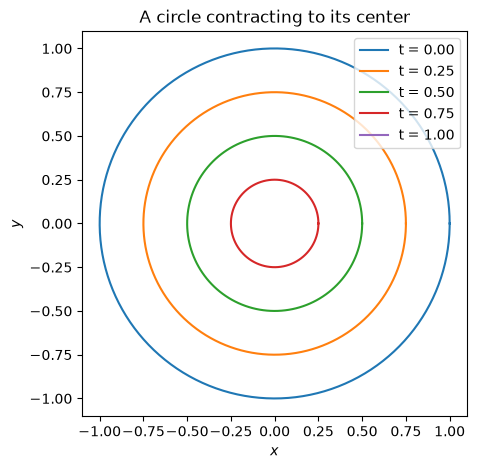

In [1]:
import numpy as np
import matplotlib.pyplot as plt

theta = np.linspace(0, 2 * np.pi, 300)
boundary = np.vstack((np.cos(theta), np.sin(theta)))

fig, ax = plt.subplots(figsize=(5, 5))
for t in np.linspace(0, 1, 5):
    scaled = (1 - t) * boundary
    ax.plot(scaled[0], scaled[1], label=f"t = {t:.2f}")

ax.set_aspect("equal")
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title("A circle contracting to its center")
ax.legend()
plt.show()

**Example:** The identity map on a disk is homotopic to a constant map, so the disk is contractible.

**Non-example:** A circle cannot be contracted to a point while remaining within the circle. Its loop cannot be shrunk away; this obstruction can be detected by invariants such as the fundamental group or first homology.

Homotopy is useful because many algebraic invariants are unchanged under homotopy equivalence.

## 5. Simplicial complexes

To compute topological information, we often replace a space by a finite combinatorial object. A **$k$-simplex** is the convex hull of $k+1$ affinely independent points:

- $0$-simplex: vertex;
- $1$-simplex: edge;
- $2$-simplex: filled triangle;
- $3$-simplex: solid tetrahedron.

A **simplicial complex** $K$ is a collection of simplices such that (i) every face of a simplex in $K$ is also in $K$, and (ii) the intersection of two simplices is empty or a face of both. The first property is closure under faces: including a filled triangle requires including all its edges and vertices.

**Example:** Three vertices, all three edges, and the filled triangle they span form a simplicial complex.

**Another example:** Three vertices and three edges, but no filled face, form a 1-dimensional simplicial complex—a triangular loop.

**Non-example:** A filled triangle with one edge omitted violates closure under faces. The distinction between a triangular loop and a filled triangle is central to homology.

### A small simplicial-complex data structure

We can store each simplex as a tuple of vertex labels. The representation below is intentionally lightweight.

### Visualizing simplices

A $k$-simplex is the convex hull of $k+1$ affinely independent points.

- A **1-simplex** is a line segment connecting two vertices.
- A **2-simplex** is a filled triangle connecting three vertices.
- A **3-simplex** is a solid tetrahedron connecting four vertices.

The following visualization draws each simplex in its natural dimension. Notice that a 2-simplex includes its interior, while a 3-simplex is a solid three-dimensional object bounded by four triangular faces.

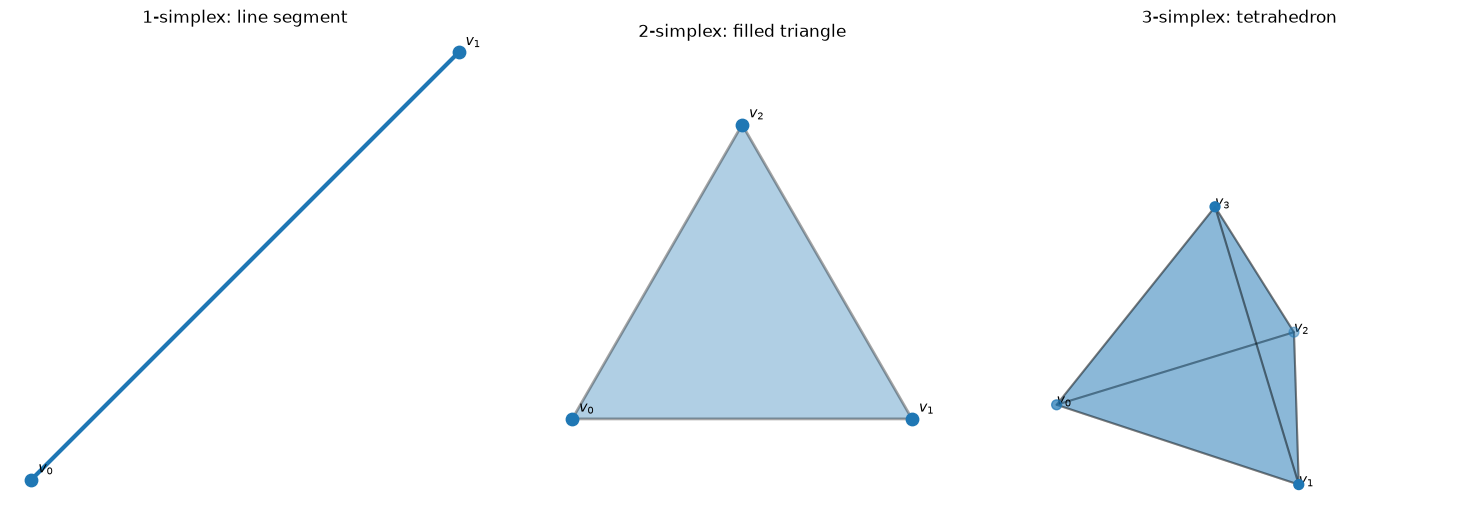

In [5]:
import numpy as np
import matplotlib.pyplot as plt

from mpl_toolkits.mplot3d.art3d import Poly3DCollection

fig = plt.figure(figsize=(15, 5))

# --------------------------------------------------
# 1. A 1-simplex: a line segment
# --------------------------------------------------
ax1 = fig.add_subplot(131)

vertices_1 = np.array([
    [0, 0],
    [1, 1]
])

ax1.plot(
    vertices_1[:, 0],
    vertices_1[:, 1],
    linewidth=3
)

ax1.scatter(
    vertices_1[:, 0],
    vertices_1[:, 1],
    s=80,
    zorder=3
)

for i, (x, y) in enumerate(vertices_1):
    ax1.annotate(f"$v_{i}$", (x, y), xytext=(5, 5),
                 textcoords="offset points")

ax1.set_title("1-simplex: line segment")
ax1.set_aspect("equal")
ax1.axis("off")


# --------------------------------------------------
# 2. A 2-simplex: a filled triangle
# --------------------------------------------------
ax2 = fig.add_subplot(132)

vertices_2 = np.array([
    [0, 0],
    [1, 0],
    [0.5, np.sqrt(3) / 2]
])

triangle = plt.Polygon(
    vertices_2,
    closed=True,
    alpha=0.35,
    edgecolor="black",
    linewidth=2
)

ax2.add_patch(triangle)
ax2.scatter(vertices_2[:, 0], vertices_2[:, 1], s=80, zorder=3)

for i, (x, y) in enumerate(vertices_2):
    ax2.annotate(f"$v_{i}$", (x, y), xytext=(5, 5),
                 textcoords="offset points")

ax2.set_xlim(-0.2, 1.2)
ax2.set_ylim(-0.2, 1.1)
ax2.set_title("2-simplex: filled triangle")
ax2.set_aspect("equal")
ax2.axis("off")


# --------------------------------------------------
# 3. A 3-simplex: a solid tetrahedron
# --------------------------------------------------
ax3 = fig.add_subplot(133, projection="3d")

vertices_3 = np.array([
    [0, 0, 0],
    [1, 0, 0],
    [0.5, np.sqrt(3) / 2, 0],
    [0.5, np.sqrt(3) / 6, np.sqrt(2 / 3)]
])

# Four triangular faces of the tetrahedron
faces = [
    [vertices_3[i] for i in face]
    for face in [
        (0, 1, 2),
        (0, 1, 3),
        (0, 2, 3),
        (1, 2, 3)
    ]
]

tetrahedron = Poly3DCollection(
    faces,
    alpha=0.3,
    edgecolor="black",
    linewidth=1.5
)

ax3.add_collection3d(tetrahedron)

ax3.scatter(
    vertices_3[:, 0],
    vertices_3[:, 1],
    vertices_3[:, 2],
    s=50
)

for i, (x, y, z) in enumerate(vertices_3):
    ax3.text(x, y, z, f"$v_{i}$")

ax3.set_xlim(0, 1)
ax3.set_ylim(0, 1)
ax3.set_zlim(0, 1)
ax3.set_box_aspect((1, 1, 1))
ax3.set_title("3-simplex: tetrahedron")

ax3.set_axis_off()

plt.tight_layout()
plt.show()

## 6. Simplicial homology

Homology is an algebraic method for detecting holes. Choose coefficients, often the field $\mathbb{F}_2$ or $\mathbb{R}$. A **$k$-chain** is a formal linear combination of $k$-simplices. Let $C_k(K)$ be the vector space generated by the $k$-simplices of $K$.

The boundary operator is a linear map

$$
\partial_k:C_k(K)\to C_{k-1}(K).
$$

For example, over $\mathbb{F}_2$,

$$
\partial_1[v_0,v_1]=[v_0]+[v_1],
$$

and

$$
\partial_2[v_0,v_1,v_2]
=[v_0,v_1]+[v_0,v_2]+[v_1,v_2].
$$

A fundamental identity is

$$
\partial_{k-1}\circ\partial_k=0,
$$

known as “the boundary of a boundary is zero.”

### Cycles, boundaries, and homology groups

A $k$-chain $z$ is a **cycle** if $\partial_k z=0$. It is a **boundary** if it is the boundary of a $(k+1)$-chain. The $k$-th homology group is

$$
H_k(K)=\ker(\partial_k)/\operatorname{im}(\partial_{k+1}).
$$

Thus, homology classes are cycles considered equivalent when their difference is a boundary. Informally:

- $H_0$ records connected components.
- $H_1$ detects independent 1-dimensional holes, such as loops not filled by 2-simplices.
- $H_2$ detects 2-dimensional voids in appropriate complexes.

When coefficients are taken in a field, $\dim H_k(K)$ is the $k$-th **Betti number** $\beta_k$.

### Visualizing cycles and boundaries

Consider a triangle with vertices $v_0,v_1,v_2$.

Its three edges form a closed loop. Over $\mathbb{F}_2$, the boundary of each edge consists of its two endpoints. When we add the boundaries of all three edges, each vertex appears twice and therefore cancels out:

$$
\partial_1([v_0,v_1]+[v_0,v_2]+[v_1,v_2])=0.
$$

Thus, the triangular loop is a **1-cycle**.

Now compare two situations:

- **Triangle boundary:** We have the three vertices and three edges, but no filled triangular face. The loop is a cycle that is not the boundary of any 2-simplex in this complex.
- **Filled triangle:** We include the 2-simplex $[v_0,v_1,v_2]$. Its boundary is precisely the three edges:

$$
\partial_2[v_0,v_1,v_2]
=[v_0,v_1]+[v_0,v_2]+[v_1,v_2].
$$

The loop is now a **boundary**, so it represents the zero class in $H_1$.

**Key idea:** A cycle has no boundary of its own; a boundary is a cycle that bounds a higher-dimensional simplex or chain. Homology detects cycles that are not boundaries.

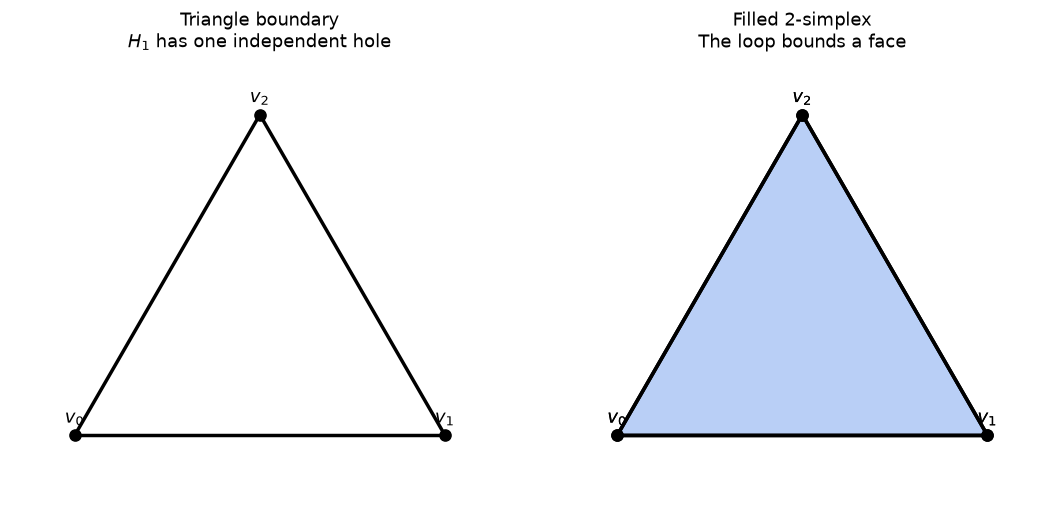

In [6]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# Three vertices of an equilateral triangle.
vertices = {
    0: (0, 0),
    1: (2, 0),
    2: (1, 1.732)
}

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax in axes:
    # Draw the three edges.
    edges = [(0, 1), (1, 2), (2, 0)]

    for i, j in edges:
        x = [vertices[i][0], vertices[j][0]]
        y = [vertices[i][1], vertices[j][1]]
        ax.plot(x, y, color="black", linewidth=2.5)

    # Draw and label vertices.
    for i, (x, y) in vertices.items():
        ax.scatter(x, y, color="black", s=65, zorder=3)
        ax.annotate(
            f"$v_{i}$",
            (x, y),
            xytext=(0, 9),
            textcoords="offset points",
            ha="center",
            fontsize=13
        )

    ax.set_aspect("equal")
    ax.set_xlim(-0.35, 2.35)
    ax.set_ylim(-0.35, 2.05)
    ax.axis("off")

# Left: boundary only.
axes[0].set_title(
    "Triangle boundary\n"
    "$H_1$ has one independent hole",
    fontsize=13
)

# Right: filled 2-simplex.
triangle = Polygon(
    [vertices[i] for i in (0, 1, 2)],
    closed=True,
    facecolor="cornflowerblue",
    edgecolor="black",
    linewidth=2.5,
    alpha=0.45,
    zorder=0
)

axes[1].add_patch(triangle)

# Redraw the edges and vertices on top of the filled face.
for i, j in [(0, 1), (1, 2), (2, 0)]:
    axes[1].plot(
        [vertices[i][0], vertices[j][0]],
        [vertices[i][1], vertices[j][1]],
        color="black",
        linewidth=2.5,
        zorder=2
    )

for i, (x, y) in vertices.items():
    axes[1].scatter(x, y, color="black", s=65, zorder=3)
    axes[1].annotate(
        f"$v_{i}$",
        (x, y),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=13
    )

axes[1].set_title(
    "Filled 2-simplex\n"
    "The loop bounds a face",
    fontsize=13
)

plt.tight_layout()
plt.show()

### Betti numbers from ranks

For a finite chain complex over a field,

$$
\beta_k=\dim C_k-\operatorname{rank}(\partial_k)
-\operatorname{rank}(\partial_{k+1}).
$$

This follows from rank-nullity and the definition of homology. For a triangular boundary, $C_0$ and $C_1$ each have dimension 3, the graph is connected, and there are no 2-simplices. Thus $\beta_0=1$ and $\beta_1=1$.

### Optional computational check using GUDHI

GUDHI is a library for computational topology. This optional cell compares Betti numbers for the triangular boundary and the filled triangle. Skip it if GUDHI is not installed.

**What the code below demonstrates:** adding the 2-simplex kills the first homology class of the triangular loop.

In [7]:
try:
    import gudhi

    boundary_complex = gudhi.SimplexTree()
    for simplex in [(0,), (1,), (2,), (0, 1), (0, 2), (1, 2)]:
        boundary_complex.insert(simplex)
    boundary_complex.compute_persistence()
    print("Triangle boundary Betti numbers:", boundary_complex.betti_numbers())

    filled_complex = gudhi.SimplexTree()
    for simplex in [
        (0,), (1,), (2,),
        (0, 1), (0, 2), (1, 2),
        (0, 1, 2)
    ]:
        filled_complex.insert(simplex)
    filled_complex.compute_persistence()
    print("Filled triangle Betti numbers:", filled_complex.betti_numbers())

except ImportError:
    print("GUDHI is not installed; skip this optional computational check.")

Triangle boundary Betti numbers: [1]
Filled triangle Betti numbers: [1, 0]


## 7. Euler characteristic

For a finite simplicial complex $K$, let $f_k$ be the number of $k$-simplices. The **Euler characteristic** is the alternating sum

$$
\chi(K)=\sum_{k\geq0}(-1)^k f_k
=f_0-f_1+f_2-f_3+\cdots.
$$

Examples:

- Triangular boundary: $f_0=3$, $f_1=3$, so $\chi=3-3=0$.
- Filled triangle: $f_0=3$, $f_1=3$, $f_2=1$, so $\chi=3-3+1=1$.

The Euler–Poincaré formula states that

$$
\chi(K)=\sum_{k\geq0}(-1)^k\beta_k.
$$

The Euler characteristic can therefore be computed either by counting simplices or by taking an alternating sum of Betti numbers, connecting combinatorics with topology.

### Compute Euler characteristic from simplex counts

**What the code below demonstrates:** it computes the simplex counts and Euler characteristic of a triangular boundary and a filled triangle.

In [8]:
def simplex_counts(simplices):
    counts = {}
    for simplex in simplices:
        dim = len(simplex) - 1
        counts[dim] = counts.get(dim, 0) + 1
    return counts

def euler_characteristic(simplices):
    counts = simplex_counts(simplices)
    return sum(((-1) ** dim) * count for dim, count in counts.items())

for name, complex_simplices in [
    ("Triangle boundary", triangle_boundary),
    ("Filled triangle", filled_triangle),
]:
    counts = simplex_counts(complex_simplices)
    print(f"{name}:")
    print("  Simplex counts by dimension:", counts)
    print("  Euler characteristic:", euler_characteristic(complex_simplices))

Triangle boundary:
  Simplex counts by dimension: {0: 3, 1: 3}
  Euler characteristic: 0
Filled triangle:
  Simplex counts by dimension: {0: 3, 1: 3, 2: 1}
  Euler characteristic: 1


## 8. Connection with geometric and topological deep learning

- **Graphs** can be viewed as 1-dimensional simplicial complexes.
- **Meshes** often encode higher-dimensional simplicial complexes with edges, faces, and sometimes tetrahedra.
- **Simplicial homology** describes connected components and higher-dimensional holes.
- **Euler characteristic** is a compact topological summary that can serve as a diagnostic or feature.

These tools do not automatically make a model topologically invariant. Rather, they provide representations and invariants useful for designing, analyzing, or evaluating models. Persistent homology extends the idea by tracking how homological features change across a filtration.

## 9. Exercises

1. Give an example of two homeomorphic spaces and two spaces that are homotopy equivalent but not homeomorphic.
2. Why must a filled triangle include all its edges and vertices to be a simplicial complex?
3. For the boundary of a tetrahedron, count vertices, edges, and triangular faces, then calculate its Euler characteristic.
4. Explain the difference between a cycle and a boundary. Why is the triangular loop nontrivial in the homology of its boundary complex but trivial in the filled triangle?
5. Compute the Euler characteristic of a square boundary and of a square triangulated into two triangles, including all faces.
6. Verify the Euler–Poincaré formula for the triangular boundary and filled triangle.
7. Explain in your own words why homotopy equivalence is weaker than homeomorphism.

## References

1. M. T. M. Bronstein, J. Bruna, T. Cohen, and P. Veličković, *Geometric Deep Learning: Grids, Groups, Graphs, Geodesics, and Gauges*, arXiv:2104.13478.
2. B. Borde and M. Bronstein, *Mathematical Foundations of Geometric Deep Learning*, arXiv:2508.02723, Sections 4.1–4.2.
3. M. A. Armstrong, *Basic Topology*, Springer, 1983; especially the discussions of homotopy, triangulations, simplicial homology, and Euler characteristic.
4. A. Hatcher, *Algebraic Topology*, Chapter 0 and Chapters 2 and 4 for geometric notions, homology, and homotopy theory. Chapter PDFs are available from the [author's page](https://pi.math.cornell.edu/~hatcher/AT/ATchapters.html).

This notebook is an educational synthesis, not a reproduction of the cited texts.